추천 결과와 재생 순서 최적화 성능을 평가

- 추천 방식 비교: 무작위 / 같은 무드 Cosine / 같은 군집 Cosine
- 순서 비교: 무작위 / 유사도순 / Nearest Neighbor / NN + 2-opt
- 곡 사이 거리는 표준화한 Feature 기준 유클리드 거리로 계산
- 무드 라벨을 같은 Feature로 만들었기 때문에 무드 일치율은 평가에서 제외

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

In [2]:
df = pd.read_csv("../data/processed/tracks_with_clusters.csv")

features = [
    "danceability",
    "energy",
    "tempo",
    "acousticness",
    "instrumentalness",
    "valence",
]

scaler = joblib.load("../models/scaler.pkl")

scaled_df = pd.DataFrame(
    scaler.transform(df[features]),
    columns=features,
    index=df.index
)

print(df.shape)

(76630, 20)


#### 추천 함수

In [3]:
def recommend(seed_index, count=19, use_cluster=True, method="cosine"):
    seed = df.loc[seed_index]

    # 같은 무드(+같은 군집)만 후보로 사용
    if use_cluster:
        candidates = df[
            (df["mood"] == seed["mood"])
            & (df["cluster"] == seed["cluster"])
        ].copy()
    else:
        candidates = df[df["mood"] == seed["mood"]].copy()

    candidates = candidates.drop(index=seed_index)

    if len(candidates) == 0:
        return candidates

    seed_vector = scaled_df.loc[[seed_index], features].to_numpy()
    candidate_vectors = scaled_df.loc[candidates.index, features].to_numpy()

    candidates["similarity"] = cosine_similarity(
        seed_vector,
        candidate_vectors
    ).flatten()

    candidates["distance"] = np.linalg.norm(
        candidate_vectors - seed_vector,
        axis=1
    )

    if method == "random":
        candidates = candidates.sample(frac=1, random_state=42 + seed_index)
    else:
        candidates = candidates.sort_values("similarity", ascending=False)

    # 같은 곡(리마스터 포함)과 같은 아티스트 반복 제한
    selected = []
    used_titles = [str(seed["track_name"]).split(" - ")[0].lower()]
    artist_count = {str(seed["artists"]).split(";")[0]: 1}

    for index, row in candidates.iterrows():
        title = str(row["track_name"]).split(" - ")[0].lower()
        artist = str(row["artists"]).split(";")[0]

        if title in used_titles:
            continue

        if artist_count.get(artist, 0) >= 2:
            continue

        selected.append(index)
        used_titles.append(title)
        artist_count[artist] = artist_count.get(artist, 0) + 1

        if len(selected) == count:
            break

    return candidates.loc[selected]

#### 순서 최적화 함수

In [14]:
def total_cost(order, vectors):
    cost = 0

    for i in range(len(order) - 1):
        cost += np.linalg.norm(vectors[order[i]] - vectors[order[i + 1]])

    return cost


def nearest_neighbor(vectors):
    order = [0]
    remaining = list(range(1, len(vectors)))

    while remaining:
        last = vectors[order[-1]]
        distances = [np.linalg.norm(vectors[i] - last) for i in remaining]
        nearest = remaining[int(np.argmin(distances))]

        order.append(nearest)
        remaining.remove(nearest)

    return order


def two_opt(order, vectors):
    best = order[:]
    best_cost = total_cost(best, vectors)
    improved = True

    while improved:
        improved = False

        for i in range(1, len(best) - 1):
            for j in range(i + 1, len(best)):
                new_order = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                new_cost = total_cost(new_order, vectors)

                if new_cost < best_cost - 1e-9:
                    best = new_order
                    best_cost = new_cost
                    improved = True

    return best


def make_playlist(seed_index, size=20):
    rec = recommend(seed_index, count=size - 1)
    index_list = [seed_index] + rec.index.tolist()
    vectors = scaled_df.loc[index_list, features].to_numpy()

    return index_list, vectors

#### 평가용 Seed 선정

무드별로 15곡씩 랜덤 추출 (총 105곡)

In [5]:
seeds = []

for mood in sorted(df["mood"].unique()):
    mood_seeds = df[df["mood"] == mood].sample(15, random_state=42)
    seeds += mood_seeds.index.tolist()

print("Seed 수:", len(seeds))

Seed 수: 105


#### 추천 방식 비교

In [6]:
methods = [
    ("random", True, "random"),
    ("cosine_same_mood", False, "cosine"),
    ("cosine_same_cluster", True, "cosine"),
]

rows = []

for seed_index in seeds:
    for name, use_cluster, method in methods:
        rec = recommend(seed_index, 19, use_cluster, method)

        rows.append({
            "seed_index": seed_index,
            "mood": df.loc[seed_index, "mood"],
            "method": name,
            "mean_similarity": rec["similarity"].mean(),
            "mean_distance": rec["distance"].mean(),
            "artist_count": rec["artists"].str.split(";").str[0].nunique(),
            "genre_count": rec["track_genre"].nunique(),
        })

recommend_result = pd.DataFrame(rows)

recommend_summary = recommend_result.groupby("method")[
    ["mean_similarity", "mean_distance", "artist_count", "genre_count"]
].mean()

recommend_summary

,mean_similarity,mean_distance,artist_count,genre_count
method,,,,
cosine_same_cluster,0.980,0.599,18.229,12.686
cosine_same_mood,0.981,0.600,18.210,12.686
random,0.659,1.998,18.629,14.324


#### 순서 방식 비교

In [ ]:
random_state = np.random.RandomState(42)
rows = []

for seed_index in seeds:
    index_list, vectors = make_playlist(seed_index)
    n = len(index_list)

    if n < 3:
        continue

    similarity_order = list(range(n))
    nn_order = nearest_neighbor(vectors)
    opt_order = two_opt(nn_order, vectors)

    random_costs = []
    for _ in range(10):
        random_order = [0] + random_state.permutation(range(1, n)).tolist()
        random_costs.append(total_cost(random_order, vectors))

    rows.append({
        "seed_index": seed_index,
        "mood": df.loc[seed_index, "mood"],
        "random": np.mean(random_costs),
        "similarity": total_cost(similarity_order, vectors),
        "nn": total_cost(nn_order, vectors),
        "nn_2opt": total_cost(opt_order, vectors),
    })

order_result = pd.DataFrame(rows)

order_cols = ["random", "similarity", "nn", "nn_2opt"]
order_summary = order_result[order_cols].mean().to_frame("mean_cost")

order_summary["vs_random_%"] = (
    (1 - order_summary["mean_cost"] / order_summary.loc["random", "mean_cost"]) * 100
)
order_summary["vs_similarity_%"] = (
    (1 - order_summary["mean_cost"] / order_summary.loc["similarity", "mean_cost"]) * 100
)

order_summary

,mean_cost,vs_random_%,vs_similarity_%
random,13.280,0.000,-2.818
similarity,12.916,2.741,0.000
nn,7.887,40.610,38.936
nn_2opt,7.404,44.249,42.678


In [8]:
print("NN+2-opt가 유사도순보다 비용이 낮은 Seed 비율:",
      round((order_result["nn_2opt"] < order_result["similarity"]).mean() * 100, 1), "%")

print("NN+2-opt가 무작위보다 비용이 낮은 Seed 비율:",
      round((order_result["nn_2opt"] < order_result["random"]).mean() * 100, 1), "%")

order_result.groupby("mood")[order_cols].mean()

NN+2-opt가 유사도순보다 비용이 낮은 Seed 비율: 100.0 %
NN+2-opt가 무작위보다 비용이 낮은 Seed 비율: 100.0 %


,random,similarity,nn,nn_2opt
mood,,,,
chill,13.000,12.873,7.450,7.029
dreamy,15.047,15.144,9.196,8.691
energetic,10.219,9.870,6.037,5.637
focus,18.241,17.335,11.173,10.434
happy,10.988,10.568,6.336,6.011
romantic,14.267,13.536,8.201,7.612
sad,11.199,11.087,6.818,6.412


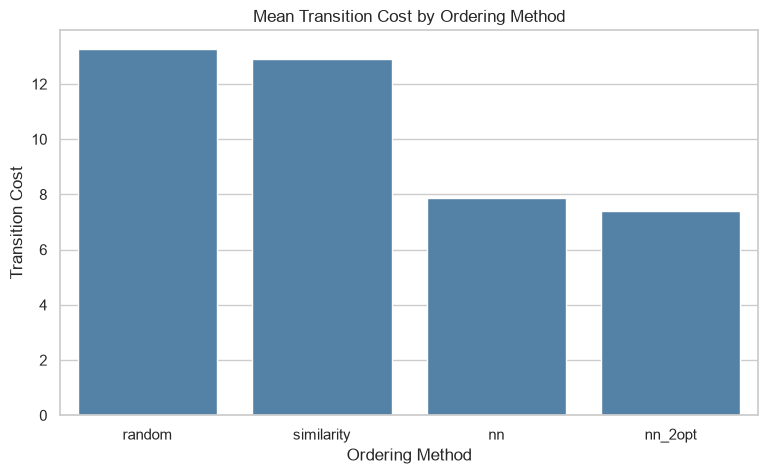

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=order_cols,
    y=order_result[order_cols].mean().values,
    color="steelblue"
)

plt.title("Mean Transition Cost by Ordering Method")
plt.xlabel("Ordering Method")
plt.ylabel("Transition Cost")
plt.show()

#### 예시 플레이리스트

In [10]:
seed_index = seeds[0]

index_list, vectors = make_playlist(seed_index)
order = two_opt(nearest_neighbor(vectors), vectors)

playlist = df.loc[[index_list[i] for i in order]].copy()
playlist.insert(0, "order", range(1, len(playlist) + 1))

similarity = cosine_similarity(vectors[[0]], vectors).flatten()
playlist["similarity"] = [similarity[i] for i in order]

print("Seed:", df.loc[seed_index, "track_name"], "-", df.loc[seed_index, "artists"])
print("전환 비용:", round(total_cost(order, vectors), 3))

playlist[["order", "track_name", "artists", "track_genre", "mood", "similarity"]]

Seed: Korkuyu Al İçimden - Eskitilmiş Yaz
전환 비용: 6.346


,order,track_name,artists,track_genre,mood,similarity
75424,1,Korkuyu Al İçimden,Eskitilmiş Yaz,turkish,chill,1.000
54931,2,Não Tem pra Ninguém - Ao Vivo,Jeito Moleque,pagode,chill,0.995
11674,3,I Love It When It Rains,The Wiggles;Marlee Matlin,children,chill,0.975
33135,4,Jumper - 1998 Edit,Third Eye Blind,grunge,chill,0.991
24560,5,Renegade,Kavinsky;Cautious Clay,electronic,chill,0.971
69536,6,Me Sabe Mal,MARLENA,spanish,chill,0.973
10647,7,Sold On Love,Frankie Knuckles,chicago-house,chill,0.985
16965,8,Skitsamma,Allyawan,dancehall,chill,0.973
25718,9,Free Fallin',Tom Petty,folk,chill,0.973
22620,10,Sleeping Bag O Wire,Groundation;Ijahman Levi,dub,chill,0.972


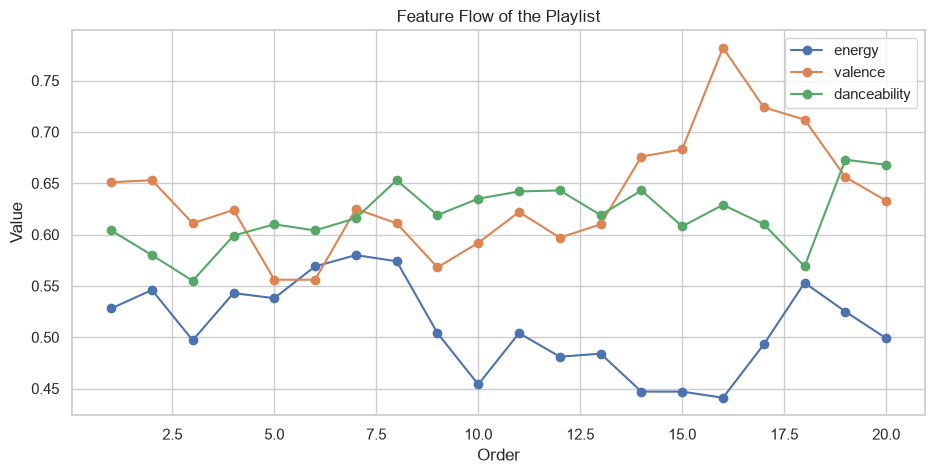

In [11]:
plt.figure(figsize=(11, 5))

for feature in ["energy", "valence", "danceability"]:
    plt.plot(playlist["order"], playlist[feature], marker="o", label=feature)

plt.title("Feature Flow of the Playlist")
plt.xlabel("Order")
plt.ylabel("Value")
plt.legend()
plt.show()

#### 확인

In [12]:
index_list_again, _ = make_playlist(seed_index)
main_artist = playlist["artists"].str.split(";").str[0]

print("같은 입력, 같은 결과:", index_list == index_list_again)
print("Seed가 첫 곡:", playlist.index[0] == seed_index)
print("중복 곡 수:", playlist["track_id"].duplicated().sum())
print("아티스트 최대 곡 수:", main_artist.value_counts().max())

같은 입력, 같은 결과: True
Seed가 첫 곡: True
중복 곡 수: 0
아티스트 최대 곡 수: 2


In [13]:
Path("../reports").mkdir(exist_ok=True)

recommend_summary.to_csv("../reports/eval_recommend_summary.csv", encoding="utf-8-sig")
recommend_result.to_csv("../reports/eval_recommend_by_seed.csv", index=False, encoding="utf-8-sig")
order_summary.to_csv("../reports/eval_order_summary.csv", encoding="utf-8-sig")
order_result.to_csv("../reports/eval_order_by_seed.csv", index=False, encoding="utf-8-sig")

playlist[["order", "track_id", "track_name", "artists", "track_genre", "similarity"]].to_csv(
    "../reports/optimized_playlist.csv", index=False, encoding="utf-8-sig"
)

## 평가 결과

#### 추천 방식 비교
Seed 105곡, 곡당 19곡 추천 기준

- 평균 Cosine 유사도: 무작위 0.659, 같은 무드 0.981, 같은 군집 0.980
- Seed와의 평균 거리: 무작위 1.998, Cosine 추천 약 0.60
- 같은 무드와 같은 군집의 차이가 거의 없어서 군집 필터의 추가 효과는 확인하지 못함

#### 순서 방식 비교
평균 전환 비용 기준

- 무작위 13.28 / 유사도순 12.92 / NN 7.89 / NN + 2-opt 7.40
- NN + 2-opt는 무작위보다 44.2%, 유사도순보다 42.7% 낮음
- 105개 Seed 모두에서 NN + 2-opt의 비용이 더 낮음
- 유사도순은 무작위와 거의 차이가 없어서, 비슷한 곡을 모으는 것과 자연스러운 순서는 별개임

#### 한계
- 무드 라벨이 오디오 Feature로 만든 규칙 기반이라 무드 일치율은 평가하지 않음
- 추천 곡이 평균 13개 장르에 퍼져 있어서 Feature가 비슷해도 실제로 들었을 때의 느낌은 다를 수 있음
- 사용자 평가로 추가 검증 필요